# Tuning de las tres primeras familias por negocio

Preparado sin salidas hasta que termine `tuning`. Los espacios y las semillas fueron fijados antes de la comparación definitiva. Se usa RandomizedSearchCV con configuraciones preextraídas: controla el presupuesto y permite escalas logarítmicas sin una grilla desproporcionada. Cada configuración es una corrida hija de su familia, con cinco folds y refit.

La selección del top 3 usa cobertura de Fail, no AP. Si el LLM ocupa una de esas posiciones, participa con sus treinta configuraciones; su tuning ajusta ejemplos y temperatura local de puntuación, no los pesos del GPT.


In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p/'config/protocolo-v2.json').is_file()), None)
if ROOT is None and (here/'pset_3/config/protocolo-v2.json').is_file(): ROOT=here/'pset_3'
assert ROOT is not None, 'Ejecutar desde pset_3 o notebooks; revisar README'
os.environ['PSET3_V2_ROOT'] = str(ROOT)
sys.path.insert(0, str(ROOT))
from src.seguimiento import protocolo
from src.common import sha256
plan = protocolo()
def report(relative):
    path = ROOT/relative
    if not path.is_file():
        raise RuntimeError('Etapa pendiente: falta '+relative+'. Revisar docs/estado-v2.json y esperar al coordinador; no sustituir por resultados de v1.')
    return json.loads(path.read_text())
print('Protocolo verificado:', plan['id'])
print('Este notebook consulta resultados reales y reproduce sus cálculos; no inicia nuevas búsquedas ni llamadas de inferencia API.')


Protocolo verificado: 07111fdf724a0cd8936ea5abc0ff983769f15d0f6216b24172c56aaf18e8ab0d
Este notebook consulta resultados reales y reproduce sus cálculos; no inicia nuevas búsquedas ni llamadas de inferencia API.


In [2]:
tuned = report('docs/tuning/resultados.json')
search = report('docs/tuning/plan.json')
assert tuned['status']=='complete' and tuned['protocol_id']==plan['id']
assert len(tuned['families'])==3 and len(tuned['configurations'])>=90
assert tuned['holdout_evaluated'] is False
from src.tuning import choose
from src.negocio import normalized
models = report('docs/modelos/resultados.json')
summary=[]
for family in tuned['families']:
    trials=[normalized(r) for r in tuned['configurations'] if r['family']==family]
    assert len(trials)>=30 and len({json.dumps(r['params'],sort_keys=True) for r in trials})>=30
    default=next(r for r in models['candidates'] if r['family']==family)
    best=choose(trials)
    spread=max(default['cv_coverage_std'],best['cv_coverage_std'])
    delta=best['cv_coverage_mean']-default['cv_coverage_mean']
    summary.append({'familia':family,'configuraciones':len(trials),'cobertura_default':default['cv_coverage_mean'],
                    'cobertura_tuned':best['cv_coverage_mean'],'DE_tuned':best['cv_coverage_std'],
                    'delta':delta,'variacion_referencia':spread,'mejora_supera_variacion':delta>spread,
                    'AP_tuned':best['cv_ap_fail_mean'],'run_id':best['run_id'],'parametros':best['params']})
    print(family,'| valores predeclarados de cada parámetro:')
    draws=search['content']['draws'][family]
    display(pd.DataFrame(draws).describe(include='all').T)
display(pd.DataFrame(summary))


lineal | valores predeclarados de cada parámetro:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
C,30.0,NaN,NaN,NaN,5.322059,9.286502,0.001952,0.023413,0.427993,8.139461,42.982763
class_weight,15,1,balanced,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max_iter,30.0,NaN,NaN,NaN,700.0,272.915296,300.0,600.0,600.0,1000.0,1000.0
tol,30.0,NaN,NaN,NaN,0.00024,0.000292,0.000012,0.000029,0.000105,0.000322,0.000941


boosting | valores predeclarados de cada parámetro:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
early_stopping,30,2,False,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
l2_regularization,30.0,NaN,NaN,NaN,0.19322,0.35387,0.000251,0.001156,0.004353,0.227999,1.321655
learning_rate,30.0,NaN,NaN,NaN,0.074991,0.049476,0.021518,0.031436,0.065068,0.117226,0.181344
max_depth,24.0,NaN,NaN,NaN,5.166667,2.200132,3.0,3.0,5.0,8.0,8.0
max_iter,30.0,NaN,NaN,NaN,106.666667,46.485692,60.0,60.0,100.0,160.0,160.0
max_leaf_nodes,30.0,NaN,NaN,NaN,28.333333,20.187626,7.0,9.0,31.0,31.0,63.0
min_samples_leaf,30.0,NaN,NaN,NaN,38.666667,27.384029,10.0,20.0,30.0,70.0,80.0


bayes | valores predeclarados de cada parámetro:


,count,mean,std,min,25%,50%,75%,max
var_smoothing,30.0,0.000084,0.000229,2.733367e-12,1.209900e-10,1.355576e-08,6.428685e-07,0.000825


,familia,configuraciones,cobertura_default,cobertura_tuned,DE_tuned,delta,variacion_referencia,mejora_supera_variacion,AP_tuned,run_id,parametros
0,lineal,30,0.229226,0.232359,0.005617,0.003134,0.008012,False,0.556657,bb2b400975994efdb01ea418118dda67,"{'C': 0.0019517224641449498, 'class_weight': '..."
1,boosting,30,0.228074,0.233982,0.009338,0.005908,0.009338,False,0.583027,dc2fa9bb8bee4944bd00611a6ac5c34f,"{'early_stopping': False, 'l2_regularization':..."
2,bayes,30,0.227818,0.228240,0.010213,0.000422,0.010680,False,0.538137,e7c7aeb2d49b4f14bdbcbe39b30197c7,{'var_smoothing': 0.0008250782956906394}


In [3]:
trials_table=pd.DataFrame([{k:v for k,v in r.items() if k not in ['folds','warnings']} for r in tuned['configurations']])
display(trials_table[['family','config_index','cv_coverage_mean','cv_coverage_std','cv_ap_fail_mean','train_ap_fail_mean','ap_gap','search_seconds','run_id']].sort_values(['family','cv_coverage_mean'],ascending=[True,False]))


,family,config_index,cv_coverage_mean,cv_coverage_std,cv_ap_fail_mean,train_ap_fail_mean,ap_gap,search_seconds,run_id
60,bayes,0,0.228240,0.010213,0.538120,0.543962,0.005842,2.065606,ef131bf00c874f459cdf5b8ebda059bb
72,bayes,12,0.228240,0.010213,0.538137,0.543997,0.005860,2.350282,e7c7aeb2d49b4f14bdbcbe39b30197c7
76,bayes,16,0.228240,0.010213,0.537989,0.543851,0.005862,2.037712,837ae2becd194906bd0db91a5bae66ef
88,bayes,28,0.228032,0.010556,0.537712,0.543430,0.005718,2.361806,39ca98b951b94c4090492a9ae2ffda47
61,bayes,1,0.227818,0.010680,0.537542,0.543219,0.005677,2.129800,bc9e44eef97d4f8892b325c01926fc92
...,...,...,...,...,...,...,...,...,...
25,lineal,25,0.227678,0.007596,0.555623,0.572746,0.017123,5.653748,53aeb1403c464dc39ec4f41ff297f0c5
3,lineal,3,0.227476,0.009291,0.555831,0.572173,0.016342,3.187864,b8962546e8d3400c8e8c18d85773c9df
20,lineal,20,0.227473,0.006401,0.556200,0.572537,0.016338,6.180870,356445a399ac4e34856bf1eda813f315
22,lineal,22,0.227280,0.007485,0.555389,0.571925,0.016537,3.455809,00a4f38502be48aeb95dc1918cab45b4


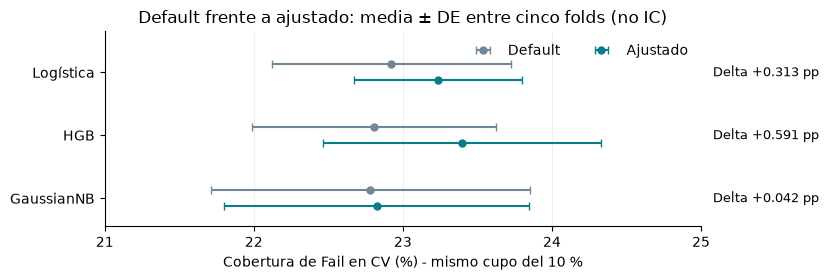

Segmentos = DE entre folds, no IC. Los deltas no superan la dispersión: sin mejora demostrada.


In [4]:
sys.path.insert(0, str(ROOT/'scripts'))
from figura_tuning import resumen_tuning, figura_matplotlib
import matplotlib.pyplot as plt
plot_rows = resumen_tuning(ROOT)
figure = figura_matplotlib(plot_rows)
figure.savefig(ROOT/'docs/tuning/default_vs_ajustado.svg', bbox_inches='tight')
figure.savefig(ROOT/'docs/tuning/default_vs_ajustado.png', dpi=300, bbox_inches='tight')
display(figure)
plt.close(figure)
print('Segmentos = DE entre folds, no IC. Los deltas no superan la dispersión: sin mejora demostrada.')


## Decisión sobre la mejora

Se informa el delta frente al default y se contrasta con la mayor desviación de ambos modelos. Ese criterio es descriptivo, tal como pide la rúbrica; no constituye una prueba de significancia con folds independientes. La elección de la mayor media de cobertura se distingue de la afirmación de una mejora estable. Los defaults siguen siendo elegibles si el tuning no los supera. Ningún resultado de prueba se utiliza para cambiar esta decisión.
